In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

# noinspection PyUnresolvedReferences
from models import bom
# noinspection PyUnresolvedReferences
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/mouse-2019-stringer/import/models/hgm.py'>

In [3]:
default_hyperparameters = {
	'max_epochs': 3000,
	'max_patience': 3000 / 4,
	'learning_rate': 1E-0,
	'dimensions': 1,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'loss1_lambda': 0.67,
	'loss2_lambda': 1.0 - 0.67,
	'w1_reg_lambda': 0.0,
	'w2_reg_lambda': 0.0,
}

# Functions

In [4]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [5]:
def train_model(model, splits, N, B_ll, B_hl, hyperparams=None):
	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	global default_hyperparameters
	hyperparameters = default_hyperparameters.copy()
	if hyperparams is not None:
		for key in hyperparams:
			hyperparameters[key] = hyperparams[key]

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	n_dimensions = hyperparameters['dimensions']

	lambdas = Lambdas(
		loss_lambdas=(hyperparameters['loss1_lambda'], hyperparameters['loss2_lambda']),
		reg_lambdas=(hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']),
		cca_lambdas=(hyperparameters['ccadiag_lambda'], hyperparameters['ccaunit_lambda'])
	)
	#endregion ===========================================================================

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop ==============================
	params_per_split = list()
	(losses_train_per_split,
	 man_losses_train_per_split,
	 res_losses_train_per_split,
	 mpe_losses_train_per_split) = list(), list(), list(), list()
	(losses_per_split,
	 man_losses_per_split,
	 res_losses_per_split,
	 mpe_losses_per_split) = list(), list(), list(), list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		N_train, N_eval = jnp.array(N[train]), jnp.array(N[eval])
		B_hl_train, B_hl_eval = jnp.array(B_hl[train]), jnp.array(B_hl[eval])
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])

		params = model.init_params(N_train, B_hl_train,
								   seeds,
								   (n_neurons, n_dimensions),
								   (n_behaviors_hl, n_dimensions),
								   (n_behaviors_ll, n_neurons),
								   * ((n_dimensions, n_neurons),) if model.get_type() else (),
								  )

		optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(init_value=learning_rate, decay_steps=max_epochs, alpha=1E-4))
		# optimizer = optax.adam(learning_rate=learning_rate)
		optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		(losses_train,
		 man_losses_train,
		 res_losses_train,
		 mpe_losses_train) = [], [], [], []
		(losses,
		 man_losses,
		 res_losses,
		 mpe_losses) = [], [], [], []

		best_params = params
		(best_loss_train,
		 best_man_loss_train,
		 best_res_loss_train,
		 best_mpe_loss_train) = sys.float_info.max, sys.float_info.max, sys.float_info.max, sys.float_info.max
		(best_loss,
		 best_man_loss,
		 best_res_loss,
		 best_mpe_loss) = sys.float_info.max, sys.float_info.max, sys.float_info.max, sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):

			(loss,
			 man_loss,
			 res_loss,
			 mpe_loss) = tuple(l.item() for l in model.loss_fn_flattened(params, N_eval, B_ll_eval, B_hl_eval, lambdas))

			(opt_state, params, loss_types_train) = model.update(optimizer.update, opt_state, params, N_train, B_ll_train, B_hl_train, lambdas)

			(loss_train,
			 man_loss_train,
			 res_loss_train,
			 mpe_loss_train) = tuple(l.item() for l in loss_types_train)

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					(best_loss_train,
					 best_man_loss_train,
					 best_res_loss_train,
					 best_mpe_loss_train) = loss_train, man_loss_train, res_loss_train, mpe_loss_train
					(best_loss,
					 best_man_loss,
					 best_res_loss,
					 best_mpe_loss) = loss, man_loss, res_loss, mpe_loss
				else:
					patience += 1
					if patience > max_patience:
						params = best_params

						losses_train = losses_train + [best_loss_train for _ in range(max_epochs - epoch)]
						man_losses_train = man_losses_train + [best_man_loss_train for _ in range(max_epochs - epoch)]
						res_losses_train = res_losses_train + [best_res_loss_train for _ in range(max_epochs - epoch)]
						mpe_losses_train = mpe_losses_train + [best_mpe_loss_train for _ in range(max_epochs - epoch)]

						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						man_losses = man_losses + [best_man_loss for _ in range(max_epochs - epoch)]
						res_losses = res_losses + [best_res_loss for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses_train.append(loss_train)
			man_losses_train.append(man_loss_train)
			res_losses_train.append(res_loss_train)
			mpe_losses_train.append(mpe_loss_train)

			losses.append(loss)
			man_losses.append(man_loss)
			res_losses.append(res_loss)
			mpe_losses.append(mpe_loss)

		params_per_split.append(params)

		losses_train_per_split.append(losses_train)
		man_losses_train_per_split.append(man_losses_train)
		res_losses_train_per_split.append(res_losses_train)
		mpe_losses_train_per_split.append(mpe_losses_train)

		losses_per_split.append(losses)
		man_losses_per_split.append(man_losses)
		res_losses_per_split.append(res_losses)
		mpe_losses_per_split.append(mpe_losses)

		print(f'Split {s_id} completed. ', end='')

	# ============================================

	# return (this also moves the data to the CPU)
	return (params_per_split,
			np.array(losses_train_per_split), np.array(man_losses_train_per_split), np.array(res_losses_train_per_split), np.array(mpe_losses_train_per_split),
			np.array(losses_per_split), np.array(man_losses_per_split), np.array(res_losses_per_split), np.array(mpe_losses_per_split))

In [6]:
def train_models(model, filenames, continuous_behaviors, motion_pcs, traces, hyperparams=None, save_name=None):
	models_params = list()
	models_losses, models_man_losses, models_res_losses, models_mpe_losses = list(), list(), list(), list()
	models_losses_train, models_man_losses_train, models_res_losses_train, models_mpe_losses_train = list(), list(), list(), list()

	for i in range(len(filenames)):
		print(f'\n{i+1}/{len(filenames)}: {filenames[i]}... ', end='')

		# splitting
		behavior = continuous_behaviors[i][['running_speed']].values
		classes = behavior > np.quantile(behavior, 0.05)
		splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces[i].shape[0]), classes))

		(params_per_split,
		 losses_train_per_split, man_losses_train_per_split, res_losses_train_per_split, mpe_losses_train_per_split,
		 losses_per_split, man_losses_per_split, res_losses_per_split, mpe_losses_per_split
		 ) = train_model(model, splits,
						 traces[i].values,
						 motion_pcs[i].values,
						 continuous_behaviors[i].values,
						 hyperparams)

		models_params.append(params_per_split)

		models_losses_train.append(losses_train_per_split)
		models_man_losses_train.append(man_losses_train_per_split)
		models_res_losses_train.append(res_losses_train_per_split)
		models_mpe_losses_train.append(mpe_losses_train_per_split)

		models_losses.append(losses_per_split)
		models_man_losses.append(man_losses_per_split)
		models_res_losses.append(res_losses_per_split)
		models_mpe_losses.append(mpe_losses_per_split)

	if save_name is not None:
		train_utils.save_params(filenames, models_params, save_name)
		train_utils.save_losses(filenames, [
			np.array([models_losses_train[i], models_man_losses_train[i], models_res_losses_train[i], models_mpe_losses_train[i],
					  models_losses[i], models_man_losses[i], models_res_losses[i], models_mpe_losses[i]]) for i in range(len(filenames))
		], save_name)

	return (models_params,
			models_losses_train, models_man_losses_train, models_res_losses_train, models_mpe_losses_train,
			models_losses, models_man_losses, models_res_losses, models_mpe_losses)

# read & prep

In [7]:
bom_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w1_reg_lambda': 2.8E-02,  #1E-2,
}
hgm_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	# 'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
	'w1_reg_lambda': 4.4E-03,  #3E-3,
	'w2_reg_lambda': 5.6E-07,  #1E-7,
}


selection_t = 2000
selection_n = 4
selection_bhl = ['running_speed', 'pupil_area']  # whisking?


npx = True
# read_ids = list(range(0, 8+1))
read_ids = [3]
plot_id = 3

In [8]:
path = os.path.join(read_utils.get_data_path(), 'mouse-2019-stringer/6163622/sessions')

(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_data(path, read_ids, with_whisking=True)

In [9]:
# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' for n_id in range(traces[i].shape[1])
	])

# GCAMP

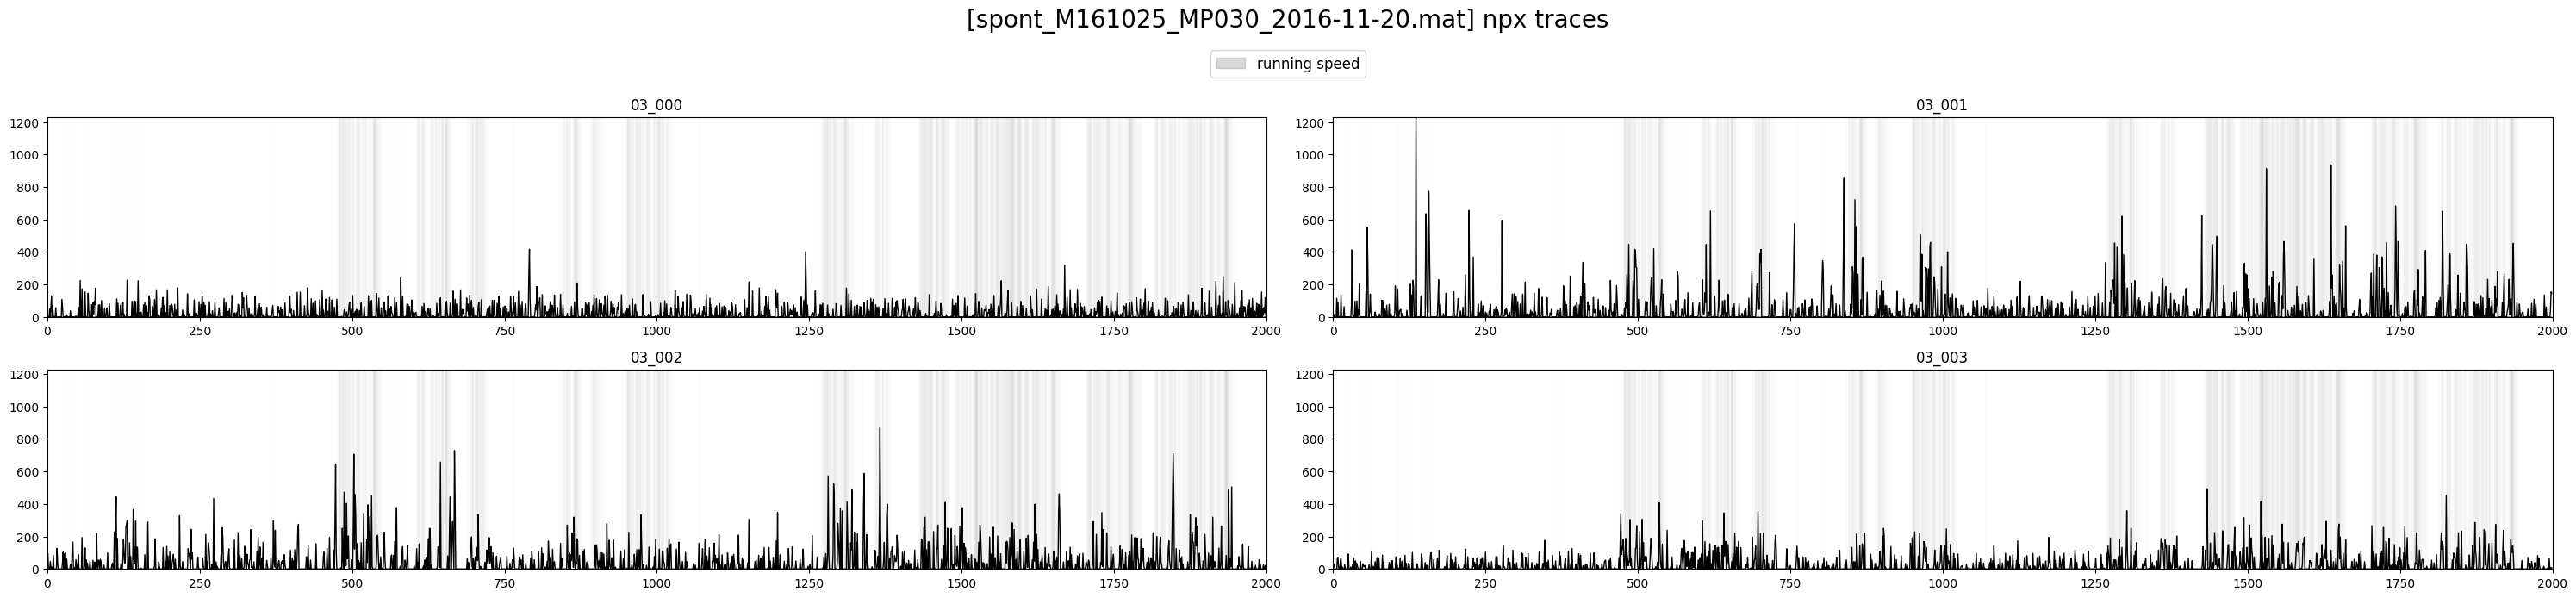

In [11]:
if npx:
	plot_utils.plot_traces_states(f'[{filenames[file_ids.index(plot_id)]}] npx traces',
								  continuous_behaviors[file_ids.index(plot_id)][['running_speed']].iloc[:selection_t, :selection_n],
								  traces[file_ids.index(plot_id)].iloc[:selection_t, :selection_n],
								  plots_per_row=2, ylimits=None)

### BOM

In [14]:
if npx:
	(boms_params,
	 boms_losses_train, boms_man_losses_train, boms_res_losses_train, boms_mpe_losses_train,
	 boms_losses, boms_man_losses, boms_res_losses, boms_mpe_losses,
	 ) = train_models(bom,
					  filenames,
					  [cb[selection_bhl] for cb in continuous_behaviors],
					  [mpcs[0] for mpcs in motion_pcs],
					  traces,
					  hyperparams=bom_reg_lamdas,
					  save_name=f'bom_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None


1/1: spont_M161025_MP030_2016-11-20.mat... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 

### HGM

In [ ]:
if npx:
	(hgms_params,
	 hgms_losses_train, hgms_man_losses_train, hgms_res_losses_train, hgms_mpe_losses_train,
	 hgms_losses, hgms_man_losses, hgms_res_losses, hgms_mpe_losses,
	 ) = train_models(hgm,
					  filenames,
					  continuous_behaviors,
					  [mpcs[0] for mpcs in motion_pcs],
					  traces,
					  hyperparams=hgm_reg_lamdas,
					  save_name=f'hgm_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None

### losses

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: train',
								  filenames,
								  hgms_losses_train, boms_losses_train,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: man train',
								  filenames,
								  hgms_man_losses_train, boms_man_losses_train,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: res train',
								  filenames,
								  hgms_res_losses_train, boms_res_losses_train,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: mpe train',
								  filenames,
								  hgms_mpe_losses_train, boms_mpe_losses_train,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: test',
								  filenames,
								  hgms_losses, boms_losses,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: man test',
								  filenames,
								  hgms_man_losses, boms_man_losses,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: res test',
								  filenames,
								  hgms_res_losses, boms_res_losses,
								  ylimits=None)

In [ ]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: mpe test',
								  filenames,
								  hgms_mpe_losses, boms_mpe_losses,
								  ylimits=None)